Edited from the 2020 Pier data example in class as well as the Lecture 3 code.

In [1]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt

SENTINEL = os.path.join('data', 'scripps_pier-2021.nc')

In [2]:
def _find_pier_file():
    """Locate data/scripps_pier-2021.nc without hard-coding anyone's home
    directory.  This module knows where IT lives, so the data must be its
    sibling: python_code/ and data/ are both inside the class repo."""
    here = os.path.dirname(os.path.abspath(__file__))   # .../python_code
    repo = os.path.dirname(here)                        # .../SIO221a_Github_code
    repo = os.path.dirname(repo)  #hack to get up to the correct directory
    for cand in (os.path.join(repo, SENTINEL),
                 os.path.join(os.environ.get('SIO221A_ROOT', ''), SENTINEL)):
        if os.path.isfile(cand):
            return cand
    print(cand)
    raise FileNotFoundError(
        f'Could not find {SENTINEL}.  Expected it inside your clone of '
        'SIO221a_Github_code, next to python_code.')


@dataclass
class PierData:
    """A slice of the 2021 pier record. """
    dnum: np.ndarray          # times, as numpy datetime64[s]
    temperature: np.ndarray   # degrees C
    pressure: np.ndarray      # decibars
    readme: str = field(
        default='2021 Pier data, SIO221a, function get_2021_pier_data.py')

    def __len__(self):
        return len(self.dnum)


def get_2021_pier_data(date_start=None, date_end=None, file=None):
    """Return temperature, pressure and time from the 2020 Scripps pier record.

    Parameters
    ----------
    date_start, date_end : numpy datetime64 or str, optional
        Bracket the period you want, e.g. '2020-06-04'.  Omit both to get the
        whole record.
    file : str, optional
        Path to the netCDF file.  Omit it and we find data/scripps_pier-2020.nc
        inside the class repo.

    Returns
    -------
    pier : PierData
    """
    if file is None:
        file = _find_pier_file()

    nc = Dataset(file)
    try:
        time = np.asarray(nc.variables['time'][:])
        temperature = np.asarray(nc.variables['temperature'][:])
        pressure = np.asarray(nc.variables['pressure'][:])
    finally:
        nc.close()

    # netCDF time is seconds since 1970-01-01, which is exactly datetime64[s].
    dnum = time.astype('datetime64[s]')

    if date_start is None:
        i1 = np.ones(dnum.shape, dtype=bool)
    else:
        i1 = ((dnum > np.datetime64(date_start)) &
              (dnum < np.datetime64(date_end)))

    return PierData(dnum=dnum[i1],
                    temperature=temperature[i1],
                    pressure=pressure[i1])

def plot_pier_data(pier):
    
    plt.figure(figsize = (10,5))
    plt.plot(pier.dnum, pier.temperature, linewidth = 1)
    plt.xlabel("Date", fontsize = 14)
    plt.minorticks_on()
    plt.ylabel("Temperature (°C)", fontsize = 14)
    plt.xticks(rotation=45)
    plt.show()


## Question One
a) 

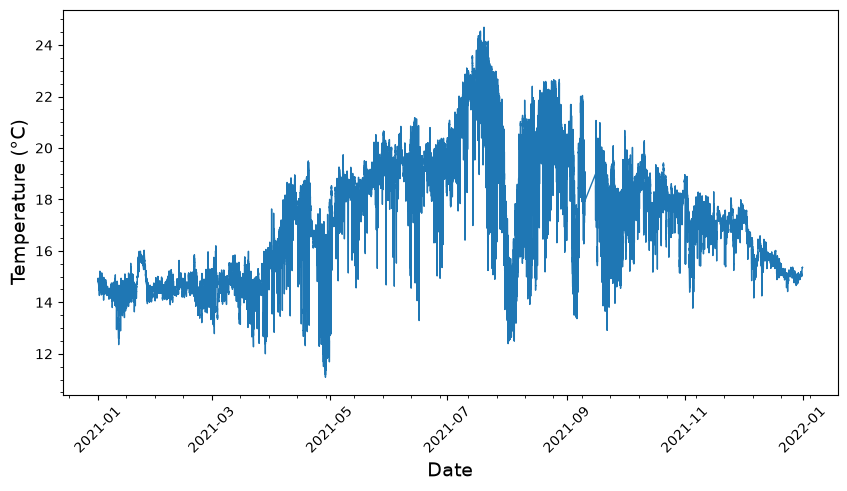

In [3]:
pier = get_2021_pier_data(file = "../pier_data/scripps_pier-2021.nc")
plot_pier_data(pier)

I notice that there is a similar pattern to the 2020 dataset, with more variety of temperatures in the summer months until September. There is a clear cyclic pattern to the data, probably owing somewhat to the tides as was discussed in class. In early August, the temperature seems to trend towards lower temperatures (it looks like on the order of days as opposed to a daily cycling of temperatures).

In [4]:
np.mean(pier.temperature), np.std(pier.temperature)

(np.float32(17.273985), np.float32(2.4253633))

The pier surface temperature in 2021 averaged 17.27°C $\pm$ 2.43°C. This doesn't seem like a particularly large variation in temperatures overall. The standard deviation tells us how much variation in the temperature there typically was.

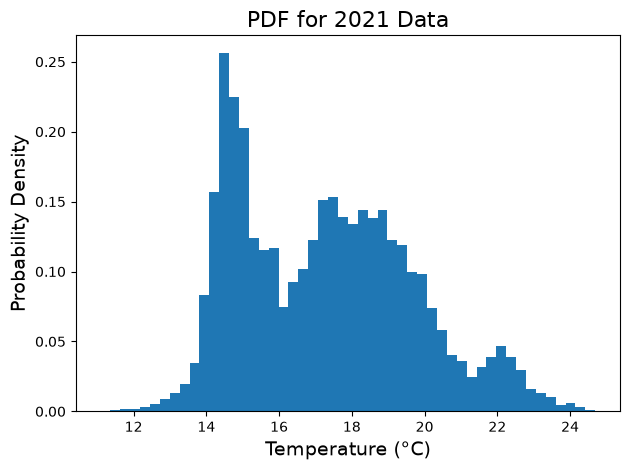

In [5]:
pdf = plt.hist(pier.temperature, bins=50, density=True)
plt.ylabel('Probability Density', fontsize=14)
plt.xlabel('Temperature (°C)', fontsize=14)
plt.title('PDF for 2021 Data', fontsize=16)
plt.tight_layout()
plt.show()

The data appears bimodal for the 2021 temperature data. There is one peak around 15°C and another near 18°C. The bimodal peaks looks slightly closer together than the one shown in class, but it still looks reasonably similar.

##Question 2

In [8]:
pier_data = {"dnum":np.array([], dtype='datetime64[s]'), "temperature":np.array([])} #make an initial dictionary to append all the data to
for i in range(2005,2022):
    pier = get_2021_pier_data(file= "../pier_data/scripps_pier-"+str(i)+".nc")
    pier_data["dnum"] = np.concatenate((pier_data["dnum"], pier.dnum)) #preserve the order, append new values to the end
    pier_data["temperature"] = np.concatenate((pier_data["temperature"], pier.temperature))

In [9]:
np.where(pier_data["temperature"] == max(pier_data["temperature"]))

pier_data["dnum"] = np.delete(pier_data["dnum"],26494) #remove the value of 97° and the corresponding time measurement
pier_data["temperature"] = np.delete(pier_data["temperature"],26494)

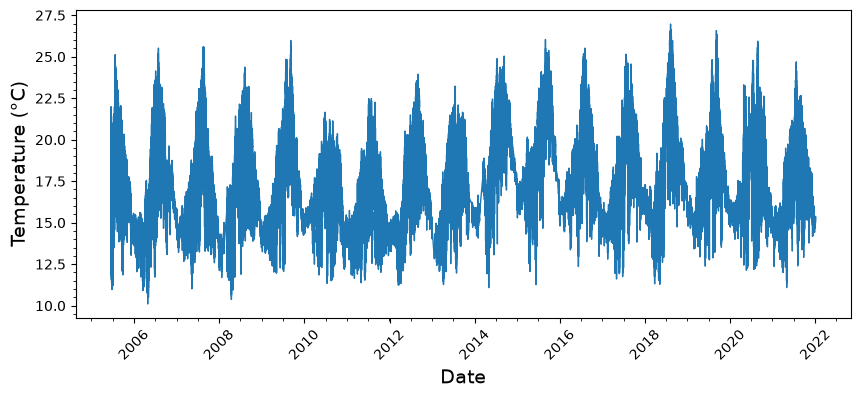

In [10]:
plt.figure(figsize = (10,4))
plt.plot(pier_data["dnum"], pier_data["temperature"], linewidth = 1)
plt.xlabel("Date", fontsize = 14)
plt.minorticks_on()
plt.ylabel("Temperature (°C)", fontsize = 14)
plt.xticks(rotation=45)
plt.show()

I notice a general yearly variation that was visible in the 2021 results. This looks reasonably similar for the different years.

In [88]:
np.mean(pier_data["temperature"]), np.std(pier_data["temperature"])

(np.float64(17.799107756283437), np.float64(2.738793548815153))

The average over all 2005-2021 was 17.90°C $\pm$ 2.74°C, while the data from only 2021 had an average water temperature of 17.27°C $\pm$ 2.43°C. These values, both the average and the standard deviation, are much closer to each other than I expected. I expected greater variability from the different years, but the temperature appears consistent.

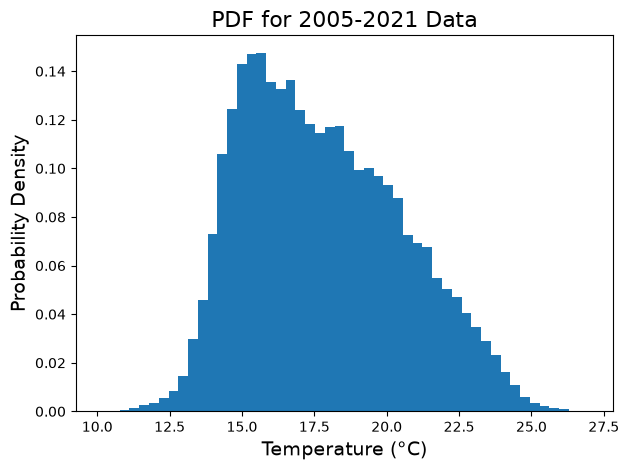

In [89]:
pdf = plt.hist(pier_data["temperature"], bins=50, density=True)
plt.ylabel('Probability Density', fontsize=14)
plt.xlabel('Temperature (°C)', fontsize=14)
plt.title('PDF for 2005-2021 Data', fontsize=16)
plt.tight_layout()
plt.show()

This pdf is much more surprising than the other results. Where 2021 had a reasonably bimodal distribution, this one has a unimodal smooth distribution. It appears mildly skewed right.